# Análisis categórico de datos de Dengue

Este notebook reproduce, desde el dataset crudo, todo lo que aparece en el README del
repositorio: las frecuencias de cada variable, la tabla de contingencia, los dos gráficos
y las pruebas de independencia entre el serotipo y la detección del virus.

Autora: **Rocío Sandez**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, fisher_exact

datos = pd.read_csv("../dengue_clase2.txt", sep="\t")
print(f"{len(datos)} muestras, columnas: {list(datos.columns)}")
datos.head()

300 muestras, columnas: ['Detecta', 'Serotipo']


,Detecta,Serotipo
0,SI,DEN-1
1,SI,DEN-1
2,SI,DEN-1
3,SI,DEN-1
4,SI,DEN-1


## Frecuencias de cada variable

Dos variables categóricas: el serotipo del virus y si la detección dio positiva o negativa.

In [2]:
def frecuencias(columna):
    conteo = datos[columna].value_counts()
    return pd.DataFrame({
        "muestras": conteo,
        "porcentaje": (100 * conteo / len(datos)).round(1),
    }).rename_axis(columna)

frecuencias("Serotipo")

,muestras,porcentaje
Serotipo,,
DEN-1,186,62.0
DEN-4,108,36.0
DEN-2,6,2.0


In [3]:
frecuencias("Detecta")

,muestras,porcentaje
Detecta,,
SI,232,77.3
NO,68,22.7


## Tabla de contingencia

Cruzando las dos variables se ve cómo se reparten las 300 muestras.

In [4]:
contingencia = pd.crosstab(datos["Serotipo"], datos["Detecta"])[["NO", "SI"]]

con_totales = contingencia.copy()
con_totales["Total"] = con_totales.sum(axis=1)
con_totales.loc["Total"] = con_totales.sum()
con_totales

Detecta,NO,SI,Total
Serotipo,,,
DEN-1,53,133,186
DEN-2,6,0,6
DEN-4,9,99,108
Total,68,232,300


Las frecuencias absolutas por sí solas no dicen mucho, porque los tres serotipos no
aparecen la misma cantidad de veces. Lo que importa es qué proporción de cada serotipo dio
positiva, es decir las frecuencias relativas por fila.

In [5]:
por_fila = (100 * contingencia.div(contingencia.sum(axis=1), axis=0)).round(1)
por_fila

Detecta,NO,SI
Serotipo,,
DEN-1,28.5,71.5
DEN-2,100.0,0.0
DEN-4,8.3,91.7


## Gráficos

Estas son las dos figuras que aparecen en el README. Se generan acá, así que cualquiera
puede volver a producirlas a partir del dataset.

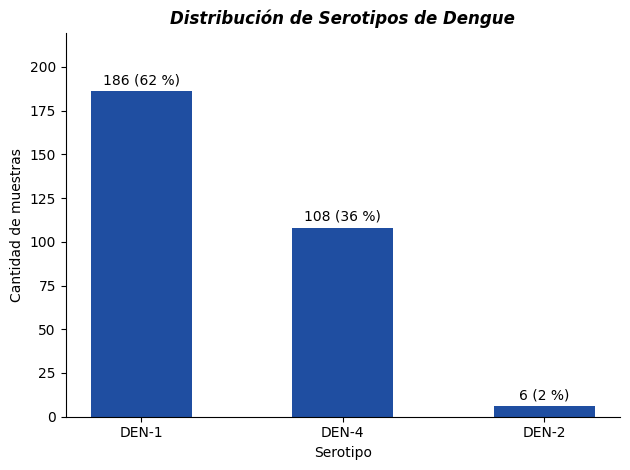

In [6]:
def barras(columna, orden, titulo, archivo):
    conteo = datos[columna].value_counts()
    categorias = [c for c in orden if c in conteo]
    valores = [conteo[c] for c in categorias]

    fig, ax = plt.subplots(figsize=(6.4, 4.8), dpi=100)
    barras_ = ax.bar(categorias, valores, color="#1f4ea1", width=0.5)
    ax.bar_label(
        barras_,
        labels=[f"{v} ({100 * v / len(datos):.0f} %)" for v in valores],
        padding=3, fontsize=10,
    )
    ax.set_title(titulo, fontsize=12, style="italic", weight="bold")
    ax.set_xlabel(columna)
    ax.set_ylabel("Cantidad de muestras")
    ax.set_ylim(0, max(valores) * 1.18)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(f"../images/{archivo}")
    return fig

barras("Serotipo", ["DEN-1", "DEN-4", "DEN-2"],
       "Distribución de Serotipos de Dengue", "frecuencias_serotipos.png");

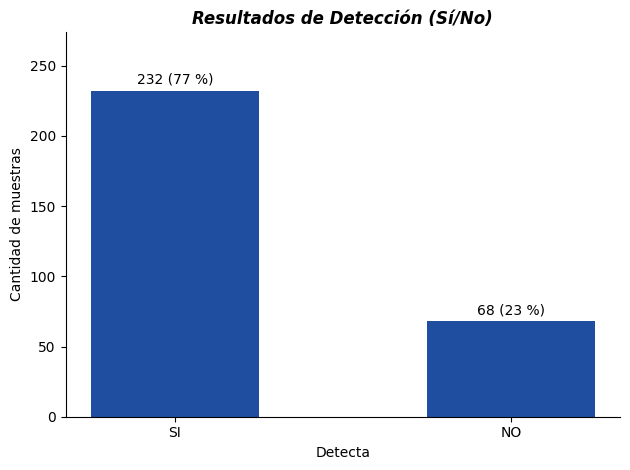

In [7]:
barras("Detecta", ["SI", "NO"],
       "Resultados de Detección (Sí/No)", "deteccion_virus.png");

## ¿El serotipo y la detección son independientes?

Las proporciones por fila son bien distintas entre serotipos, pero una diferencia puede
aparecer por azar. La prueba de χ² de independencia compara lo observado contra lo que se
esperaría si las dos variables no tuvieran relación.

In [8]:
chi2, p, gl, esperadas = chi2_contingency(contingencia)
print(f"χ² = {chi2:.2f}    gl = {gl}    p = {p:.2e}")

pd.DataFrame(esperadas, index=contingencia.index,
             columns=contingencia.columns).round(2)

χ² = 36.73    gl = 2    p = 1.06e-08


Detecta,NO,SI
Serotipo,,
DEN-1,42.16,143.84
DEN-2,1.36,4.64
DEN-4,24.48,83.52


El resultado da significativo, pero antes de quedarse con él hay que mirar la tabla de
frecuencias esperadas: la prueba de χ² pide que todas sean de al menos 5, y la fila de
DEN-2 queda muy por debajo porque son apenas 6 muestras.

Por eso repito el contraste sin DEN-2, comparando sólo DEN-1 contra DEN-4 con la prueba
exacta de Fisher, que no necesita ese supuesto.

In [9]:
sub = contingencia.loc[["DEN-1", "DEN-4"]]
odds, p_fisher = fisher_exact(sub.values)
print(sub, end="\n\n")
print(f"odds ratio = {odds:.3f}    p = {p_fisher:.2e}")

Detecta   NO   SI
Serotipo         
DEN-1     53  133
DEN-4      9   99

odds ratio = 4.383    p = 2.63e-05


## Conclusión

La detección depende del serotipo: dio positiva en el 72 % de las muestras de DEN-1 y en el
92 % de las de DEN-4, y en ninguna de las 6 de DEN-2. La diferencia es estadísticamente
significativa, tanto con χ² sobre la tabla completa como con la prueba exacta de Fisher
entre los dos serotipos con suficientes muestras.

Vale aclarar qué *no* dice esto. Son datos de una práctica, no de un estudio
epidemiológico, y una tasa de detección distinta según el serotipo puede deberse al método
de detección o a cómo se armó la muestra, antes que a la biología del virus. El caso de
DEN-2 son 6 muestras: con tan pocas, cero positivos no alcanza para concluir nada.